In [120]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import src.helper
import src.plots
import src.spectra
from scipy.optimize import curve_fit

In [121]:
MEASUREMENT_PERIOD = 1 / 12  # 2 hour timestep
TIME_BANDWIDTH_PRODUCT = 3

SEMIDIURNAL_TIDAL_CONSTITUENTS = src.helper.get_tidal_frequencies_in_hours(tide_type="continuum")
# # sort the constituents in descending order after their tidal periods
# # This is important for finding overlapping tidal peaks
SEMIDIURNAL_TIDAL_CONSTITUENTS = dict(
    sorted(SEMIDIURNAL_TIDAL_CONSTITUENTS.items(), key=lambda x: x[1], reverse=True)
)

In [122]:
# load all 7 moorings as dataframes
list_of_moorings = src.helper.load_pickle(name="../../data/mooring/list_of_moorings.pkl")
mooring_C = src.helper.load_pickle(name="../preprocessing/mooring_C.pkl")
region_categorization = pd.read_csv("../../derived_data/rcm_infos.csv", index_col=0)
names = ["A", "B", "C", "D", "E", "F", "G"]
moorings = {}
for name, mooring in zip(names, list_of_moorings, strict=False):
    moorings[name] = mooring.set_index("time")
    print(mooring.location, list(mooring.columns))

(-63.40,-52.29) ['time', '299', '505', '614']
(-63.51,-51.64) ['time', '1318', '1513', '1625']
(-63.66,-50.81) ['time', '2143', '2350', '750']
(-63.78,-50.09) ['time', '2400', '2615', '2724']
(-63.92,-49.27) ['time', '3036', '3299', '3358']
(-64.07,-48.38) ['time', '3835']
(-64.22,-47.49) ['time', '4120', '4160']


In [123]:
nsquared_data = src.helper.load_pickle("../../derived_data/nsquared_data_at_measurements.pkl")
nsquared_data_at_C = nsquared_data["C"][2350]
nsquared_data_at_C

2017-01-26    0.000002
2017-01-27    0.000002
2017-01-28    0.000001
2017-01-29    0.000003
2017-01-30    0.000002
                ...   
2019-01-25    0.000003
2019-01-26    0.000003
2019-01-27    0.000002
2019-01-28    0.000002
2019-01-29    0.000002
Freq: D, Name: 2350, Length: 734, dtype: float64

In [139]:
# from prep
best_guess_barotropic_energy_at_C = pd.read_csv(
    "./best_guess_barotropic_energy_at_C.csv", index_col=0
)
index_list = []
for index in best_guess_barotropic_energy_at_C.index:
    _, indexa, _, indexb, _ = index.split("'")
    index_list.append((pd.to_datetime(indexa), pd.to_datetime(indexb)))
best_guess_barotropic_energy_at_C.index = np.array(index_list)  # .astype(str)

In [140]:
best_guess_barotropic_energy_at_C

,0
"(2017-01-28 00:00:00, 2017-02-27 00:00:00)",0.000181
"(2017-02-02 00:00:00, 2017-03-04 00:00:00)",0.000201
"(2017-02-07 00:00:00, 2017-03-09 00:00:00)",0.000214
"(2017-02-12 00:00:00, 2017-03-14 00:00:00)",0.000196
"(2017-02-17 00:00:00, 2017-03-19 00:00:00)",0.000221
...,...
"(2018-12-09 00:00:00, 2019-01-08 00:00:00)",0.000138
"(2018-12-14 00:00:00, 2019-01-13 00:00:00)",0.000156
"(2018-12-19 00:00:00, 2019-01-18 00:00:00)",0.000155
"(2018-12-24 00:00:00, 2019-01-23 00:00:00)",0.000135


In [126]:
def find_latest_start(moorings):
    starttimes = []
    for i, (name, mooring) in enumerate(moorings.items()):
        for j, col in enumerate(mooring.columns):
            if name == "C":
                series = pd.Series(
                    index=mooring_C[f"time_{col}"].values, data=mooring_C[col].values
                )
            else:
                series = mooring[col]
            starttimes.append(series.index[0])

    latest_start = np.max(np.array(starttimes))
    return latest_start


common_start_time = pd.to_datetime(find_latest_start(moorings)).round("h")
print(f"{common_start_time = }")

common_start_time = Timestamp('2017-01-28 12:00:00')


In [127]:
def cut_to_f_N_interval(freq, psd, f, N):
    f_index = np.argmin(np.abs(freq - f))
    N_index = np.argmin(np.abs(freq - N))

    fN_freq_interval = freq[f_index:N_index]
    fN_psd = psd[f_index:N_index]

    if np.shape(fN_freq_interval) == np.shape([]):
        raise AssertionError

    return fN_freq_interval, fN_psd


def get_integration_intervals_for_tidal_peaks(freq, P, tidal_periods):
    integration_indices_intervals = []

    # get interval of width 2P for each tidal frequency
    for tidal_period in tidal_periods:
        tidal_freq_in_cpd = 24 / tidal_period
        tidal_index = np.argmin(np.abs(freq - (tidal_freq_in_cpd)))
        width = (tidal_index - P, tidal_index + P + 1)
        integration_indices_intervals.append(width)

    # because the peaks all have the same width 2P, I can check the ascending order
    # by checking if the start or the end points are in ascending order. I test here both to be extra sure
    def is_monotonic_increasing(L):
        return all(x <= y for x, y in zip(L, L[1:], strict=False))

    # slicing a list of tuples is complicated
    interval_start_points = list(zip(*integration_indices_intervals, strict=False))[0]
    try:
        assert is_monotonic_increasing(interval_start_points)
    except AssertionError as e:
        print(f"{interval_start_points =}")
        raise e

    # slicing a list of tuples is complicated
    interval_end_points = list(zip(*integration_indices_intervals, strict=False))[1]
    try:
        assert is_monotonic_increasing(interval_end_points)
    except AssertionError as e:
        print(f"{interval_end_points =}")
        raise e

    # check intervals for overlaps until none are found
    while True:
        Overlap = False
        # Iteration is over a copy to not change the object iterated over
        for i, interval in enumerate(integration_indices_intervals.copy()):
            if i + 1 == len(integration_indices_intervals):
                break
            next_interval = integration_indices_intervals[i + 1]

            start1, end1 = interval
            start2, end2 = next_interval

            if end1 >= start2 and end2 >= start1:
                Overlap = True
                integration_indices_intervals[i] = (start1, end2)
                integration_indices_intervals[i + 1] = (start1, end2)

        # remove duplicated intervals
        # by creating a dictionary with the tuples as keys and None values and then converting back to list
        integration_indices_intervals = list(dict.fromkeys(integration_indices_intervals))

        if not Overlap:
            break
    return integration_indices_intervals


def get_mean_N_squared_in_chunk(chunk_time_index, N_squared_series):

    try:
        assert N_squared_series.index[0] <= chunk_time_index[0]
        assert N_squared_series.index[-1] >= chunk_time_index[-1]
        return N_squared_series.loc[chunk_time_index[0] : chunk_time_index[-1]].mean()

    # requested chunk is outside the given time series
    except AssertionError as e:
        print(
            "FROM: available:",
            N_squared_series.index[0],
            "requested:",
            chunk_time_index[0],
            N_squared_series.index[0] - chunk_time_index[0],
        )
        print("TO: available:", N_squared_series.index[-1], "requested:", chunk_time_index[-1])

        # time difference is small, proceed anyway
        if np.abs(N_squared_series.index[0] - chunk_time_index[0]) < pd.Timedelta(days=1):
            return N_squared_series.loc[chunk_time_index[0] : chunk_time_index[-1]].mean()

        else:
            raise e
            # return np.nan

In [128]:
def kinetic_to_total_energy(f, N, omega):
    conversion = 2 * (N**2 - f**2) / (N**2 - omega**2) * (omega**2) / (omega**2 + f**2)
    return conversion


def func_powerlaw(x, s, c):
    return x**s * c


def func_powerlaw_with_fixed_point(x, s, fph, fsh):
    return fph * fsh**-s * x**s

C, 2350m: spectral slope = -1.76, total extension energy is responsible for 21.6% of the total continuum energy
C, 2350m: available semidiurnal baroclinic energy is responsible for 37.5% of the total available energy
C, 2350m: spectral slope = -1.82, total extension energy is responsible for 20.9% of the total continuum energy
C, 2350m: available semidiurnal baroclinic energy is responsible for 37.2% of the total available energy
C, 2350m: spectral slope = -1.97, total extension energy is responsible for 20.3% of the total continuum energy
C, 2350m: available semidiurnal baroclinic energy is responsible for 36.8% of the total available energy
C, 2350m: spectral slope = -2.04, total extension energy is responsible for 18.9% of the total continuum energy
C, 2350m: available semidiurnal baroclinic energy is responsible for 34.2% of the total available energy
C, 2350m: spectral slope = -1.74, total extension energy is responsible for 26.0% of the total continuum energy
C, 2350m: available 

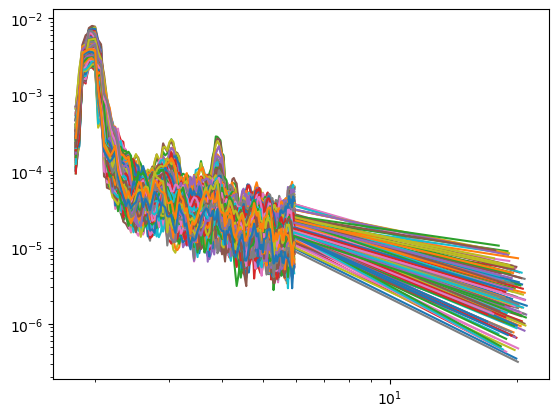

In [192]:
for i, (name, mooring) in enumerate(moorings.items()):
    for j, col in enumerate(mooring.columns):
        if name != "C" or col != str(2350):
            continue

        series = pd.Series(index=mooring_C[f"time_{col}"].values, data=mooring_C[col].values)
        series = series[series.index.dropna()]
        assert series.index.is_monotonic_increasing
        series = series.loc[pd.to_datetime(common_start_time) :]
        series = series.dropna()

        coriolis_frequency_in_cpd = src.helper.get_coriolis_frequency(
            mooring.location.lat, unit="cpd", absolute=True
        )
        coriolis_frequency_in_rads = src.helper.get_coriolis_frequency(
            mooring.location.lat, unit="rad/s", absolute=True
        )

        # timestamps = []
        available_energies = []
        chunk_bounds = []
        number_of_days: int = 30

        count = 0
        for run, chunk in enumerate(series.rolling(window=f"{number_of_days}D", center=True)):
            if run % (12 * 5) != 0:
                continue  # skip 5 days every loop

            # print(len(chunk), int(number_of_days/MEASUREMENT_PERIOD))
            if len(chunk) < int(number_of_days / MEASUREMENT_PERIOD) - 5:
                continue  # skip windows with not enough data points

            chunk_full_day = chunk.resample("D").mean()
            chunk_bound = (chunk_full_day.index[0], chunk_full_day.index[-1])
            chunk_bounds.append(chunk_bound)

            freq, velocity_spectrum = src.spectra.total_multitaper(
                chunk.values, dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
            )
            assert not np.any(np.isnan(velocity_spectrum))
            HKE_spectrum = 0.5 * velocity_spectrum
            HKE_series = pd.Series(index=freq, data=HKE_spectrum)
            maximum_resolved_N = 6
            fN_freq_interval, resolved_HKE_spectrum_between_f_and_N = cut_to_f_N_interval(
                freq, HKE_spectrum, coriolis_frequency_in_cpd, N=maximum_resolved_N
            )

            mean_N_squared_in_rads = get_mean_N_squared_in_chunk(chunk.index, nsquared_data_at_C)
            mean_N_in_rads = np.sqrt(mean_N_squared_in_rads)
            mean_N_in_cpd = mean_N_in_rads / (2 * np.pi) * 86400

            # --------------------------------------------------------------------------------------------------
            # convert resolved kinetic to resolved total (kinetic+potential) energy between f and N

            # Correction factor in cpd
            kinetic_to_total_energy_factor = kinetic_to_total_energy(
                f=coriolis_frequency_in_cpd, N=mean_N_in_cpd, omega=fN_freq_interval
            )

            # correction factor cannot be larger than 1, as HKE < HKE + APE
            try:
                assert np.all(kinetic_to_total_energy_factor > 0.999)
            except AssertionError:
                plt.plot(fN_freq_interval, kinetic_to_total_energy_factor)
                plt.show()

            # Compare to Correction factor in rad/s
            difference = kinetic_to_total_energy_factor - kinetic_to_total_energy(
                f=coriolis_frequency_in_rads,
                N=mean_N_in_rads,
                omega=fN_freq_interval * (2 * np.pi) / 86400,
            )
            try:
                assert np.all(np.abs(difference) < 1e-10)
            except AssertionError as e:
                """
                plt.plot(fN_freq_interval, kinetic_to_total_energy_factor, label="from cpd")
                plt.plot(fN_freq_interval, kinetic_to_total_energy(
                f=coriolis_frequency_in_rads, N=mean_N_in_rads, omega=fN_freq_interval * (2 * np.pi) / 86400
            ), label="from rads")
                plt.legend()
                plt.show()
                """
                raise e

            # PSD and the frequency is in units of cpd
            resolved_total_energy_spectrum_between_f_and_N = (
                kinetic_to_total_energy_factor * resolved_HKE_spectrum_between_f_and_N
            )

            # --------------------------------------------------------------------------------------------------
            # calculate resolved total energy between f and N only in the continuum (!!!) by subtracting the energy in the peaks

            # integrate spectrum from f to N to get a single number
            resolved_total_energy_between_f_and_N = src.spectra.integrate_psd_interval(
                fN_freq_interval,
                resolved_total_energy_spectrum_between_f_and_N,
                a=coriolis_frequency_in_cpd,
                b=mean_N_in_cpd,
            )

            total_energy_per_peak = []  # no physical meaning, as it did not differentiate between barotropic and baroclinic tides
            # calculate integration intervals for the tidal peaks
            integration_indices_intervals = get_integration_intervals_for_tidal_peaks(
                fN_freq_interval,
                P=TIME_BANDWIDTH_PRODUCT,
                tidal_periods=SEMIDIURNAL_TIDAL_CONSTITUENTS.values(),
            )

            # iterate over the tidal peaks and calculate energy per peak
            for interval_tuple in integration_indices_intervals:
                a = fN_freq_interval[interval_tuple[0]]
                try:
                    b = fN_freq_interval[interval_tuple[1]]
                except IndexError:
                    b = fN_freq_interval[-1]
                peak_integral = src.spectra.integrate_psd_interval(
                    fN_freq_interval, resolved_total_energy_spectrum_between_f_and_N, a=a, b=b
                )
                # compare values at the edges
                background_height = min(
                    resolved_total_energy_spectrum_between_f_and_N[interval_tuple[0]],
                    resolved_total_energy_spectrum_between_f_and_N[
                        min(interval_tuple[1], len(fN_freq_interval) - 1)
                    ],
                )
                background_integral = background_height * (b - a)
                total_energy_per_peak.append(peak_integral - background_integral)

            # all spectral energy - peak energy
            resolved_continuums_total_energy = resolved_total_energy_between_f_and_N - np.sum(
                total_energy_per_peak
            )

            # --------------------------------------------------------------------------------------------------
            # Calculate total wave continuum energy by extending the resolved continuum up to N

            # fit constant slope to the unaltered HKE spectrum
            last_freq = fN_freq_interval[-1]  # highest resolved frequency
            extent_freq = np.linspace(last_freq, mean_N_in_cpd, 20)

            start_freq = 3.2  # in cpd
            start_index = np.argmin(np.abs(fN_freq_interval - start_freq))
            x = fN_freq_interval[start_index:]
            y = resolved_HKE_spectrum_between_f_and_N[start_index:]

            popt, pcov = curve_fit(
                func_powerlaw,
                x,
                y,
                p0=np.asarray([-2, 1e4]),
                bounds=([-3, -np.inf], [-0.8, np.inf]),
            )
            fitted_slope = tuple(popt)[0]
            fitted_slope_error = np.sqrt(np.diag(pcov))[0]  # one standard deviation errors

            # fit prefactor to resolved total energy spectrum, given the determined slope
            # x (frequency range) stays the same
            y = resolved_total_energy_spectrum_between_f_and_N[start_index:]

            def func_powerlaw_total_psd(x, c):
                sptrc_slope = fitted_slope
                return x**sptrc_slope * c

            fitted_slope_height, _pcov = curve_fit(
                func_powerlaw_total_psd, x, y, p0=np.asarray([1e4])
            )

            # add energy of the spectral extension up to N to the energy calculated from the data
            extension_total_energy = src.spectra.integrate_psd_interval(
                extent_freq,
                func_powerlaw_total_psd(extent_freq, fitted_slope_height),
                a=coriolis_frequency_in_cpd,
                b=20,
            )

            plt.loglog(fN_freq_interval, resolved_HKE_spectrum_between_f_and_N, label="HKE")
            plt.loglog(fN_freq_interval, resolved_total_energy_spectrum_between_f_and_N, label="E")
            plt.loglog(
                extent_freq,
                func_powerlaw_total_psd(extent_freq, fitted_slope_height),
                label="extent",
            )
            # plt.legend()

            """
            # error calculation
            fixed_point_height = func_powerlaw_total_psd(last_freq, fitted_slope_height)

            upper_bound_extension_total_energy = (
                src.spectra.integrate_psd_interval(
                extent_freq, func_powerlaw_with_fixed_point(
                    extent_freq,
                    fitted_slope+fitted_slope_error,
                    fixed_point_height,
                    last_freq
            )))

            lower_bound_extension_total_energy = (
            src.spectra.integrate_psd_interval(
                extent_freq, func_powerlaw_with_fixed_point(
                    extent_freq,
                    fitted_slope-fitted_slope_error,
                    fixed_point_height,
                    last_freq
            )))
            assert upper_bound_extension_total_energy >= lower_bound_extension_total_energy
            error_extension_energy = 0.5*np.abs(upper_bound_extension_total_energy - lower_bound_extension_total_energy)
            """

            continuum_total_energy = resolved_continuums_total_energy + extension_total_energy
            print(
                f"{name}, {col}m: spectral slope = {fitted_slope:.2f}, total extension energy is responsible for {(extension_total_energy / continuum_total_energy):.1%} of the total continuum energy"
            )

            # --------------------------------------------------------------------------------------------------
            # Calculate available total energy at tidal frequencies, for which the baroclinic tide at this depth has to be determined first

            # start again at the HKE
            horizontal_kinetic_energy_per_peak = []  # no physical meaning, as it does not differentiate between barotropic and baroclinic tides
            # calculate integration intervals for the tidal peaks
            integration_indices_intervals = get_integration_intervals_for_tidal_peaks(
                fN_freq_interval,
                P=TIME_BANDWIDTH_PRODUCT,
                tidal_periods=SEMIDIURNAL_TIDAL_CONSTITUENTS.values(),
            )

            # iterate over the tidal peaks and calculate energy at tidal frequencies (peak + background)
            for interval_tuple in integration_indices_intervals:
                a = fN_freq_interval[interval_tuple[0]]
                try:
                    b = fN_freq_interval[interval_tuple[1]]
                except IndexError:
                    b = fN_freq_interval[-1]
                peak_integral = src.spectra.integrate_psd_interval(
                    fN_freq_interval, resolved_HKE_spectrum_between_f_and_N, a=a, b=b
                )
                horizontal_kinetic_energy_per_peak.append(peak_integral)

            # sum over energies at tidal frequencies
            horizontal_kinetic_energy_at_tidal_frequencies = np.sum(
                horizontal_kinetic_energy_per_peak
            )

            # the barotropic tide for each mooring was calculated above
            # subtract barotropic tide to get baroclinic tide
            #
            # print(count, len(best_guess_barotropic_energy_at_C))
            barotropic_kinetic_energy = best_guess_barotropic_energy_at_C.iloc[count].values
            # print(chunk_bound, best_guess_barotropic_energy_at_C.index[count])
            assert chunk_bound == best_guess_barotropic_energy_at_C.index[count]
            baroclinic_kinetic_energy = (
                horizontal_kinetic_energy_at_tidal_frequencies - barotropic_kinetic_energy
            )

            # baroclinic energy cannot be negative and is 0 in the worst case
            assert baroclinic_kinetic_energy >= 0

            # As this energy is contained in internal waves, it also must be converted to include the potential energy
            # use conversion factor value at 2 cpd, because most of the energy is located there
            two_cpd = 2
            semidiurnal_index = np.argmin(np.abs(fN_freq_interval - two_cpd))
            # assert the index is neither the start or end of the frequency array
            assert semidiurnal_index != 0 and semidiurnal_index != len(fN_freq_interval) - 1
            baroclinic_conversion_factor = kinetic_to_total_energy_factor[semidiurnal_index]

            semidiurnal_baroclinic_total_energy = (
                baroclinic_conversion_factor * baroclinic_kinetic_energy
            )

            # only higher modes (usually n>4) contain energy available for local dissipation
            # here at first assumed to be 30% of all baroclinic energy
            # Citation: Vic et al, 2019
            available_semidiurnal_baroclinic_energy = 0.3 * semidiurnal_baroclinic_total_energy

            # --------------------------------------------------------------------------------------------------
            # Combine all energies

            available_energy = float(
                np.squeeze(continuum_total_energy + available_semidiurnal_baroclinic_energy)
            )
            available_energies.append(available_energy)
            print(
                f"{name}, {col}m: available semidiurnal baroclinic energy is responsible for {np.squeeze(available_semidiurnal_baroclinic_energy / available_energy):.1%} of the total available energy"
            )

            count += 1

        available_energy_df = pd.Series(index=chunk_bounds, data=available_energies)

In [193]:
available_energy_df.to_csv("./available_energy.csv")
available_energy_df

(2017-01-28 00:00:00, 2017-02-27 00:00:00)    0.000399
(2017-02-02 00:00:00, 2017-03-04 00:00:00)    0.000413
(2017-02-07 00:00:00, 2017-03-09 00:00:00)    0.000403
(2017-02-12 00:00:00, 2017-03-14 00:00:00)    0.000427
(2017-02-17 00:00:00, 2017-03-19 00:00:00)    0.000558
                                                ...   
(2018-12-09 00:00:00, 2019-01-08 00:00:00)    0.000413
(2018-12-14 00:00:00, 2019-01-13 00:00:00)    0.000448
(2018-12-19 00:00:00, 2019-01-18 00:00:00)    0.000445
(2018-12-24 00:00:00, 2019-01-23 00:00:00)    0.000455
(2018-12-29 00:00:00, 2019-01-28 00:00:00)    0.000436
Length: 141, dtype: float64

<Axes: >

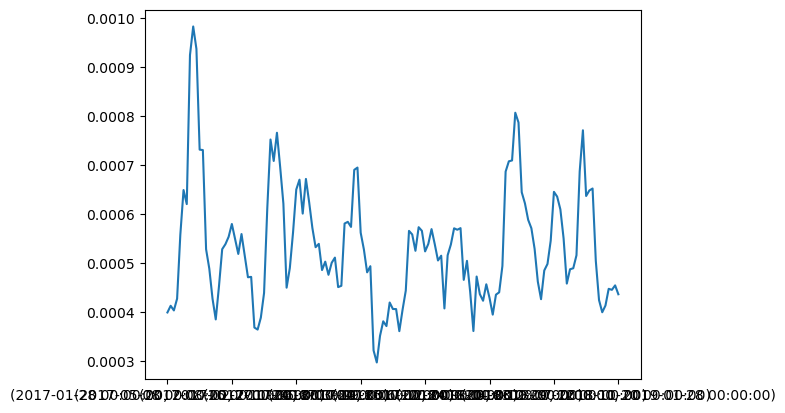

In [194]:
available_energy_df.plot()